# Análise da Campanha Mínima Viável

Métricas por réplica, critérios de aceitação (Tabela 4.6 da v0.8) e comparações pareadas entre MECADE e baseline.

Para a campanha real, `DATA_ROOT` aponta para `data/runs`. Uso `data/sim/runs` (com `INCLUDE_SIM=True`) só para testar o pipeline, e esses dados simulados não entram em nenhum resultado.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'analysis' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from analysis.metrics import audit_overhead, execution_failures, false_block_verdict, load_official_runs, load_runs, metrics_table, paired_comparison
DATA_ROOT = ROOT / 'data' / 'runs'
INCLUDE_SIM = False
FIG = ROOT / 'analysis' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
if INCLUDE_SIM:
    runs, excluidas = load_runs(DATA_ROOT, include_sim=True), []
else:  # análise oficial: só campaign_id do config, sem sim nem calibração
    runs, excluidas = load_official_runs(DATA_ROOT)
print(len(excluidas), 'réplicas excluídas:', excluidas)
m = metrics_table(runs)
print(len(runs), 'réplicas carregadas'); m.head()

0 réplicas excluídas: []


70 réplicas carregadas


,run_id,scenario,arm,pair,backend,audit,detected,TTD,TTM,TTR,...,p99_std,TSR_fault,p99_fault,classe,block,I_max,max_D,RRIndex_run,audit_p95_ms,controller_cpu_s
0,001_c0_controle_mecade_r10,c0_controle,mecade,,k8s,0,True,1150.0,NaN,600.0,...,0.372596,1.000000,0.692628,degradado,False,14.593426,3.093311,0.461616,NaN,4.407625
1,002_s1_latencia_productcatalog_baseline_r09,s1_latencia_productcatalog,baseline,s1_latencia_productcatalog#09,k8s,1,True,305.0,425.0,540.0,...,1.508350,0.274124,0.666148,critico,False,42297.152786,94.098884,0.000923,NaN,4.560576
2,003_s1_latencia_productcatalog_mecade_r09,s1_latencia_productcatalog,mecade,s1_latencia_productcatalog#09,k8s,1,True,20.0,330.0,565.0,...,1.506207,0.437640,0.877033,critico,True,32672.585455,99.176277,0.001144,0.043809,4.568818
3,004_s2_gray_currency_mecade_r06,s2_gray_currency,mecade,s2_gray_currency#06,k8s,1,True,80.0,NaN,665.0,...,2.061050,0.649376,3.543912,degradado,False,25266.734639,100.000000,0.001763,0.055809,4.504764
4,005_s2_gray_currency_baseline_r06,s2_gray_currency,baseline,s2_gray_currency#06,k8s,1,False,NaN,NaN,600.0,...,2.136199,0.686634,3.451354,degradado,False,18000.026545,88.697318,0.002757,NaN,4.467719


## 1. Visão geral por cenário e braço

In [2]:
cols = ['detected','TTD','TTM','TTR_capped','MTTR','area_incidente','p95_std','p99_std','TSR_fault','p99_fault','RRIndex_run']
main = m[m['pair'].astype(str) != '']
main.groupby(['scenario','arm'])[cols].median().round(3)

detected    TTD    TTM  TTR_capped  \
scenario                   arm                                            
s1_latencia_productcatalog baseline       1.0  305.0  427.5       540.0   
                           mecade         1.0   20.0  330.0       475.0   
s2_gray_currency           baseline       0.0    NaN    NaN       600.0   
                           mecade         1.0   80.0    NaN       622.5   
s3_podkill_cart            baseline       1.0  345.0  465.0       540.0   
                           mecade         1.0   92.5  427.5       482.5   

                                      MTTR  area_incidente  p95_std  p99_std  \
scenario                   arm                                                 
s1_latencia_productcatalog baseline  235.0       42630.468    1.279    1.514   
                           mecade    455.0       33785.522    1.276    1.486   
s2_gray_currency           baseline    NaN       19339.736    2.024    1.937   
                           mecade    545.0       19708.189    2.026    1.995   
s3_podkill_cart            baseline  192.5       34991.074    0.550    1.385   
                           mecade    380.0       31439.311    0.536    1.309   

                                     TSR_fault  p99_fault  RRIndex_run  
scenario                   arm                                          
s1_latencia_productcatalog baseline      0.291      0.768        0.001  
                           mecade        0.441      0.846        0.001  
s2_gray_currency           baseline      0.684      3.589        0.003  
                           mecade        0.678      3.557        0.003  
s3_podkill_cart            baseline      0.418      1.562        0.001  
                           mecade        0.478      1.633        0.001

## 2. Classificação tripartite (Tabela 3.5) e detecção

In [3]:
pd.crosstab([main['scenario'], main['arm']], main['classe'])

classe                               critico  degradado
scenario                   arm                         
s1_latencia_productcatalog baseline       10          0
                           mecade         10          0
s2_gray_currency           baseline        0         10
                           mecade          0         10
s3_podkill_cart            baseline       10          0
                           mecade         10          0

In [4]:
main.groupby(['scenario','arm']).agg(n=('run_id','count'), detectadas=('detected','sum'), censuradas=('censurada','sum'), rto_ok=('rto_ok','sum'))

n  detectadas  censuradas  rto_ok
scenario                   arm                                         
s1_latencia_productcatalog baseline  10          10           0       0
                           mecade    10          10           0       0
s2_gray_currency           baseline  10           0          10       0
                           mecade    10          10           0       0
s3_podkill_cart            baseline  10          10           0       5
                           mecade    10          10           0       0

In [5]:
falhas = execution_failures(DATA_ROOT)
print('falha_execucao (o par sai da comparação):', [(f['run_id'], f['pair']) for f in falhas])
print('censuradas:', list(main[main['censurada']]['run_id']))

falha_execucao (o par sai da comparação): []
censuradas: ['005_s2_gray_currency_baseline_r06', '007_s2_gray_currency_baseline_r03', '025_s2_gray_currency_baseline_r04', '028_s2_gray_currency_baseline_r09', '030_s2_gray_currency_baseline_r07', '035_s2_gray_currency_baseline_r08', '051_s2_gray_currency_baseline_r02', '061_s2_gray_currency_baseline_r01', '067_s2_gray_currency_baseline_r05', '070_s2_gray_currency_baseline_r10']


## 3. Comparações pareadas (MECADE menos baseline)

Wilcoxon pareado, delta de Cliff e IC de 95% por *bootstrap* da mediana das diferenças. Réplicas censuradas entram com o fim da janela (`_capped`), como manda a Seção 4.4.1 da v0.8.

In [6]:
pd.concat([paired_comparison(m, k) for k in ['TTD_capped','TTR_capped','MTTR_capped','area_incidente','p95_std','p99_std','RRIndex_run','TSR_fault','p99_fault']], ignore_index=True).round(4)

,scenario,metric,n_pairs,median_baseline,median_mecade,median_diff,ci95_low,ci95_high,wilcoxon_p,cliffs_delta
0,s1_latencia_productcatalog,TTD_capped,10,305.0000,20.0000,-285.0000,-285.0000,-282.5000,0.0020,-1.00
1,s2_gray_currency,TTD_capped,10,1195.0000,80.0000,-1115.0000,-1115.0005,-1115.0000,0.0020,-1.00
2,s3_podkill_cart,TTD_capped,10,345.0000,92.5000,-255.0000,-275.0000,-205.0000,0.0020,-1.00
3,s1_latencia_productcatalog,TTR_capped,10,540.0000,475.0000,-52.5000,-102.5000,-35.0000,0.0059,-0.67
4,s2_gray_currency,TTR_capped,10,600.0000,622.5000,7.5000,-10.0000,30.0000,0.4297,0.24
5,s3_podkill_cart,TTR_capped,10,540.0000,482.5000,-57.5000,-80.0000,-35.0000,0.0039,-0.72
6,s1_latencia_productcatalog,MTTR_capped,10,235.0000,455.0000,230.0000,185.0000,250.0000,0.0020,1.00
7,s2_gray_currency,MTTR_capped,10,1195.0000,545.0000,-650.0000,-675.0000,-640.0000,0.0020,-1.00
8,s3_podkill_cart,MTTR_capped,10,192.5000,380.0000,177.5000,150.0000,215.0000,0.0020,0.96
9,s1_latencia_productcatalog,area_incidente,10,42630.4678,33785.5222,-8379.8955,-12458.5342,-326.2938,0.0098,-0.80


## 4. Taxa de falsos bloqueios (réplicas de controle)

In [7]:
from mecade.config import load_campaign
v = false_block_verdict(m, load_campaign()['analysis']['false_block_max_rate'])
print(f"Controles: {v['controles']} | BLOCK acionado em {v['blocks']} => taxa de falsos bloqueios = {v['taxa']:.2%}")
print(f"Critério: taxa <= {v['limiar']:.0%} (no máximo 1 em 10) ->", v['aceito'])

Controles: 10 | BLOCK acionado em 0 => taxa de falsos bloqueios = 0.00%
Critério: taxa <= 10% (no máximo 1 em 10) -> True


## 5. Overhead da auditoria (Camada 6, perfil mínimo)

Δ_audit no caminho de decisão é o p95 do custo de enfileirar o evento. Δcpu compara a CPU do controlador nos controles com auditoria ligada e desligada.

In [8]:
aud = m[m['arm']=='mecade'].groupby('audit')[['audit_p95_ms','controller_cpu_s']].median()
print(aud)
o = audit_overhead(m); print(o)
print('Critério: Δ_audit,p95 <= 5 ms ->', o['delta_audit_p95_ms'] <= 5, '| Δcpu <= 8% ->', o['delta_cpu_pct'] <= 8)

       audit_p95_ms  controller_cpu_s
audit                                
0               NaN          4.476030
1           0.03992          4.512434
{'n_on': 5, 'n_off': 5, 'delta_audit_p95_ms': 0.04352000541985035, 'delta_cpu_pct': -2.260138620509139}
Critério: Δ_audit,p95 <= 5 ms -> True | Δcpu <= 8% -> True


## 6. Vereditos (decisão D1, 2026-11-12)

Critério por cenário: mediana da diferença pareada do lado favorável ao MECADE, IC 95% *bootstrap* sem cruzar zero e limiar da Tabela 4.6 cumprido. Hipótese: ACEITA (todos os critérios em todos os cenários), PARCIAL ou NÃO ACEITA. O mapa de critério para hipótese está em `analysis.veredito` de `config/campaign.yaml`. Componente marcada como pendente não decide, e a hipótese afetada sai PENDENTE. As proporções da H2 (`rto_ok`, `classe_pior`) usam McNemar exato sobre os pares e exigem p < 0,05 (D5). Cenário planejado sem par válido sai SEM_DADOS e impede a hipótese de ser ACEITA. A análise principal não tem correção; Holm é a secundária, com uma família por hipótese (D6).

In [9]:
from analysis.veredito import cenarios_planejados, resumo
camp = load_campaign(); cfg = camp['analysis']
plano = ROOT / 'data' / f"plan_{camp['campaign_id']}.csv"  # o plano oficial cobre o de contingência
plan_sc = cenarios_planejados(plano, camp['scenarios'], camp['control_scenario'])
print('Cenários planejados:', plan_sc)
tab_v, crit, hip, crit_holm, hip_holm = resumo(m, cfg['veredito'], cfg, cenarios=plan_sc)
print('Análise principal, sem correção')
crit

Cenários planejados: ['s1_latencia_productcatalog', 's2_gray_currency', 's3_podkill_cart']


Análise principal, sem correção


,hipotese,criterio,scenario,status,falhas,pendentes
0,H2,recuperacao,s1_latencia_productcatalog,NAO_ATENDE,MTTR_capped: mediana do lado contrário ou nula...,
1,H2,recuperacao,s2_gray_currency,NAO_ATENDE,TTR_capped: mediana do lado contrário ou nula;...,
2,H2,recuperacao,s3_podkill_cart,NAO_ATENDE,MTTR_capped: mediana do lado contrário ou nula...,
3,H2,classificacao,s1_latencia_productcatalog,NAO_ATENDE,classe_pior: diferença de proporções do lado c...,
4,H2,classificacao,s2_gray_currency,NAO_ATENDE,classe_pior: diferença de proporções do lado c...,
5,H2,classificacao,s3_podkill_cart,NAO_ATENDE,classe_pior: diferença de proporções do lado c...,
6,H1,deteccao_estabilidade,s1_latencia_productcatalog,NAO_ATENDE,p95_std: mediana do lado contrário ou nula; p9...,
7,H1,deteccao_estabilidade,s2_gray_currency,NAO_ATENDE,area_incidente: mediana do lado contrário ou n...,
8,H1,deteccao_estabilidade,s3_podkill_cart,NAO_ATENDE,p95_std: IC 95% cruza zero; p99_std: mediana d...,
9,H2,convergencia,s1_latencia_productcatalog,ATENDE,,


In [10]:
hip

,hipotese,veredito,atende,nao_atende,pendente,sem_dados,detalhe
0,H1,PARCIAL,1,3,0,0,deteccao_estabilidade/s1_latencia_productcatal...
1,H2,PARCIAL,2,7,0,0,recuperacao/s1_latencia_productcatalog=NAO_ATE...
2,H3,ACEITA,1,0,0,0,overhead_auditoria/controle=ATENDE


In [11]:
print('Análise secundária, com Holm (uma família por hipótese: H1, H2, H3)')
crit_holm

Análise secundária, com Holm (uma família por hipótese: H1, H2, H3)


,hipotese,criterio,scenario,status,falhas,pendentes
0,H2,recuperacao,s1_latencia_productcatalog,NAO_ATENDE,MTTR_capped: mediana do lado contrário ou nula...,
1,H2,recuperacao,s2_gray_currency,NAO_ATENDE,TTR_capped: mediana do lado contrário ou nula;...,
2,H2,recuperacao,s3_podkill_cart,NAO_ATENDE,MTTR_capped: mediana do lado contrário ou nula...,
3,H2,classificacao,s1_latencia_productcatalog,NAO_ATENDE,classe_pior: diferença de proporções do lado c...,
4,H2,classificacao,s2_gray_currency,NAO_ATENDE,classe_pior: diferença de proporções do lado c...,
5,H2,classificacao,s3_podkill_cart,NAO_ATENDE,classe_pior: diferença de proporções do lado c...,
6,H1,deteccao_estabilidade,s1_latencia_productcatalog,NAO_ATENDE,area_incidente: p ajustado por Holm não passa;...,
7,H1,deteccao_estabilidade,s2_gray_currency,NAO_ATENDE,area_incidente: mediana do lado contrário ou n...,
8,H1,deteccao_estabilidade,s3_podkill_cart,NAO_ATENDE,p95_std: IC 95% cruza zero; p99_std: mediana d...,
9,H2,convergencia,s1_latencia_productcatalog,NAO_ATENDE,RRIndex_run: p ajustado por Holm não passa,


In [12]:
hip_holm

,hipotese,veredito,atende,nao_atende,pendente,sem_dados,detalhe
0,H1,PARCIAL,1,3,0,0,deteccao_estabilidade/s1_latencia_productcatal...
1,H2,PARCIAL,1,8,0,0,recuperacao/s1_latencia_productcatalog=NAO_ATE...
2,H3,ACEITA,1,0,0,0,overhead_auditoria/controle=ATENDE


In [13]:
tab_v.round(4)

,scenario,metric,n_pairs,median_baseline,median_mecade,median_diff,ci95_low,ci95_high,wilcoxon_p,cliffs_delta,prop_baseline,prop_mecade,diff_prop,discordantes_mecade,discordantes_baseline,mcnemar_p,valor,p_holm
0,s1_latencia_productcatalog,MTTR_capped,10.0,235.0000,455.0000,230.0000,185.0000,250.0000,0.0020,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0293
1,s2_gray_currency,MTTR_capped,10.0,1195.0000,545.0000,-650.0000,-675.0000,-640.0000,0.0020,-1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0293
2,s3_podkill_cart,MTTR_capped,10.0,192.5000,380.0000,177.5000,150.0000,215.0000,0.0020,0.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0293
3,s1_latencia_productcatalog,TTR_capped,10.0,540.0000,475.0000,-52.5000,-102.5000,-35.0000,0.0059,-0.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0586
4,s2_gray_currency,TTR_capped,10.0,600.0000,622.5000,7.5000,-10.0000,30.0000,0.4297,0.24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0000
5,s3_podkill_cart,TTR_capped,10.0,540.0000,482.5000,-57.5000,-80.0000,-35.0000,0.0039,-0.72,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0430
6,s1_latencia_productcatalog,rto_ok,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,1.0000,NaN,1.0000
7,s2_gray_currency,rto_ok,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,1.0000,NaN,1.0000
8,s3_podkill_cart,rto_ok,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5,0.0,-0.5,0.0,5.0,0.0625,NaN,0.5000
9,s1_latencia_productcatalog,classe_pior,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0000,NaN,1.0000


## 7. Figuras

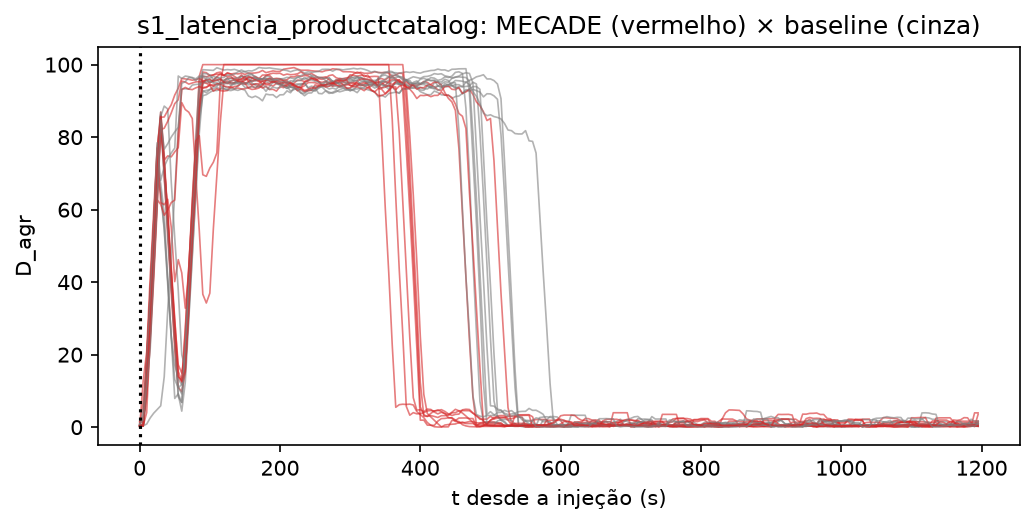

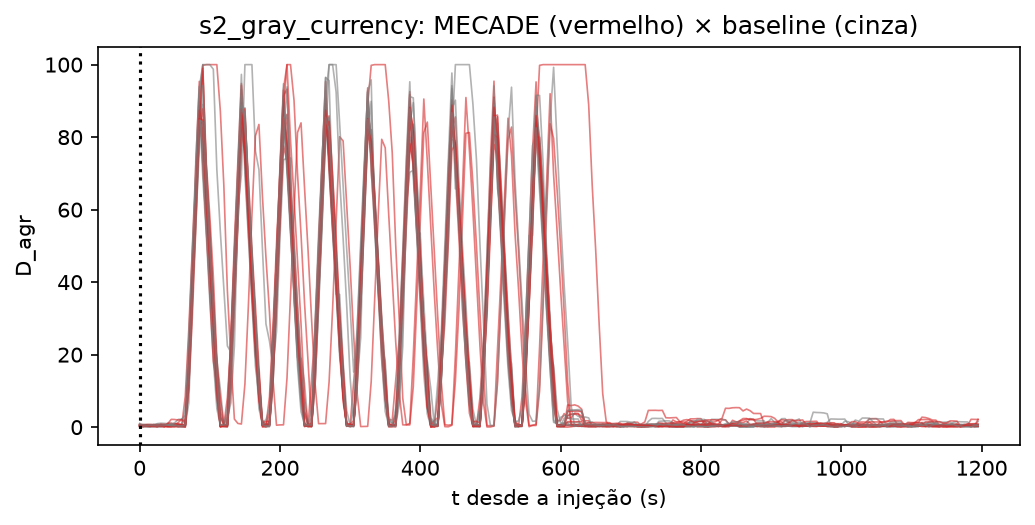

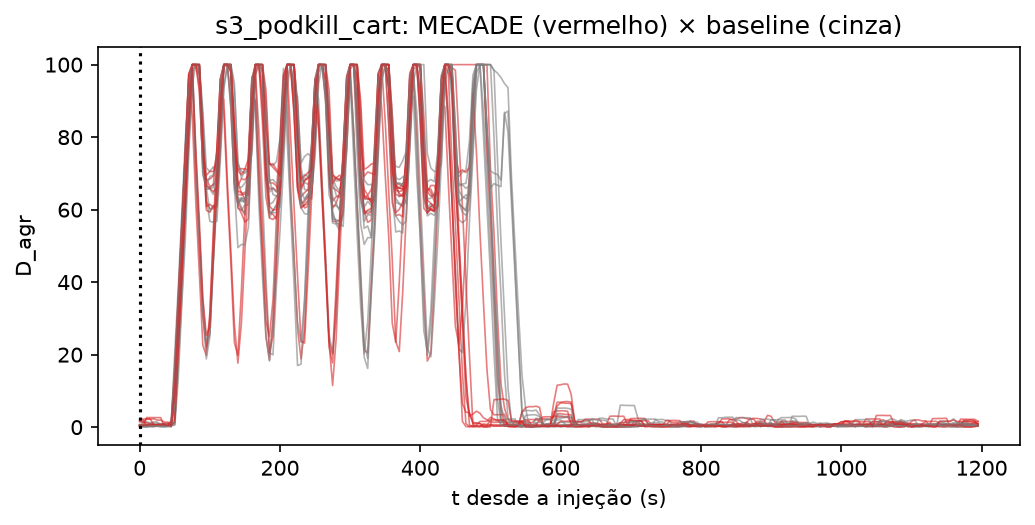

In [14]:
def fig_series(scenario):
    fig, ax = plt.subplots(figsize=(7, 3.6), dpi=150)
    for meta, df in runs:
        if meta['scenario'] != scenario or not meta.get('pair'):
            continue
        d = df[df['t'] >= 0]
        ax.plot(d['t'], d['D_agr'], lw=0.8, alpha=0.6, color='tab:red' if meta['arm']=='mecade' else 'tab:gray')
    ax.axvline(0, ls=':', c='k'); ax.set_xlabel('t desde a injeção (s)'); ax.set_ylabel('D_agr')
    ax.set_title(f'{scenario}: MECADE (vermelho) × baseline (cinza)')
    fig.tight_layout(); fig.savefig(FIG / f'Dagr_{scenario}.png', dpi=300)
for sc in sorted(main['scenario'].unique()):
    fig_series(sc)

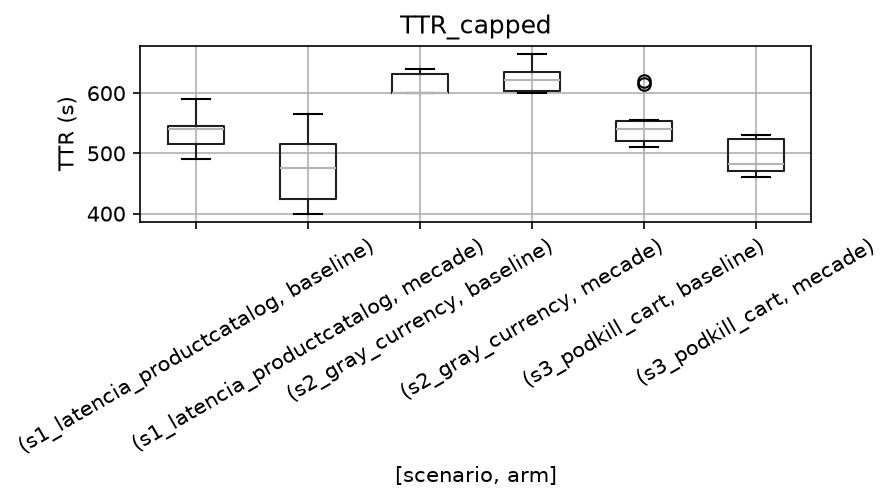

In [15]:
fig, ax = plt.subplots(figsize=(6, 3.6), dpi=150)
main.boxplot(column='TTR_capped', by=['scenario','arm'], ax=ax, rot=30)
ax.set_ylabel('TTR (s)'); plt.suptitle(''); fig.tight_layout(); fig.savefig(FIG / 'TTR_box.png', dpi=300)

## 8. Exportação para a dissertação

In [16]:
m.to_csv(ROOT / 'analysis' / 'metricas_por_replica.csv', index=False)
print('analysis/metricas_por_replica.csv gravado')

analysis/metricas_por_replica.csv gravado
